#### **Physics-Informed Neural Network (PINN) Training and Evaluation for Buckley-Leverett Flow**

##### **Purpose:** This notebook constructs, trains, and evaluates a Physics-Informed Neural Network (PINN) to solve the 1D Buckley-Leverett equation with capillary diffusion. It defines the PyTorch model architecture, formulates the physics-based loss functions (PDE residual, initial, and boundary conditions), computes the relative L2 error against the numerical FDM baseline, and exports the optimized model weights for interactive web deployment.

##### **Network & Training Overview:** The neural network features a fully connected architecture with 4 hidden layers (50 neurons each) and utilizes the SiLU (Swish) activation function to accurately resolve steep fluid displacement shock fronts. The model is trained entirely without labeled interior simulation data, relying instead on spatial-temporal collocation points optimized sequentially via Adam and L-BFGS algorithms.

##### **Author:** Bello Oluwatobi

##### **Last Updated:** October 8, 2026

### #1 Importing libraries and Environment Setup

In [ ]:
# importing libraries
import torch
import numpy as np
import matplotlib.pyplot as plt
import sys
import os

In [ ]:
# adding the parent directory to the Python path
sys.path.append(os.path.abspath('..'))
from utils.pinn_model import build_pinn_model, compute_physics_loss

In [ ]:
# enforcing random seeds to ensure reproducible collocation points and weight initialization
torch.manual_seed(42)
np.random.seed(42)

# selecting GPU if available for faster training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


### #2 Generating Training Data 

In [ ]:
def generate_training_data(N_u=1000, N_f=20000):
    """
    Generates Boundary/Initial data points (N_u) and interior Collocation points (N_f).
    Returns tensors mapped to the appropriate compute device.
    """
    # specifying Initial Conditions: @ t = 0, domain is filled with non-wetting phase (Sw = 0) 
    x_ic = np.random.uniform(0, 1, (N_u, 1))
    t_ic = np.zeros((N_u, 1))
    u_ic = np.zeros((N_u, 1))

    # specifying Boundary Conditions: @ x = 0 (inlet), domain is filled with non-wetting phase (Sw = 0) 
    x_bc = np.zeros((N_u, 1))
    t_bc = np.random.uniform(0, 1, (N_u, 1))
    u_bc = np.ones((N_u, 1))

    # combining IC and BC into a single supervised dataset
    x_data = np.vstack([x_ic, x_bc])
    t_data = np.vstack([t_ic, t_bc])
    u_data = np.vstack([u_ic, u_bc])
    
    # generating 10,000 collocation points uniformly across the domain
    x_uniform = np.random.uniform(0, 1, (N_f // 2, 1))
    t_uniform = np.random.uniform(0, 1, (N_f // 2, 1))
    
    # generating 10,000 collocation points clustered around the line x = 1.15 * t
    t_targeted = np.random.uniform(0, 1, (N_f // 2, 1))
    shock_trajectory = 1.15 * t_targeted
    
    # adding small Gaussian noise to spread points across the steep gradient
    x_targeted = shock_trajectory + np.random.normal(0, 0.06, (N_f // 2, 1))
    
    # clipping any points that fall outside the physical domain [0, 1]
    x_targeted = np.clip(x_targeted, 0.0, 1.0)
    
    # combine uniform and targeted collocation points
    x_colloc = np.vstack([x_uniform, x_targeted])
    t_colloc = np.vstack([t_uniform, t_targeted])
    
    return (torch.tensor(x_data, dtype=torch.float32).to(device), 
            torch.tensor(t_data, dtype=torch.float32).to(device), 
            torch.tensor(u_data, dtype=torch.float32).to(device),
            torch.tensor(x_colloc, dtype=torch.float32).to(device),
            torch.tensor(t_colloc, dtype=torch.float32).to(device))

# instantiating the new targeted tensors
x_data, t_data, u_data, x_colloc, t_colloc = generate_training_data()

### #3 Model Setup and Phase 1 Training (Adam)

In [ ]:
# building the Sequential model with 4 hidden layers (50 neurons each)
model = build_pinn_model(layers=[2, 50, 50, 50, 50, 1]).to(device)

# initializing Adam optimizer
optimizer_adam = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs_adam = 4000

# introducing a physics loss weight
lambda_data = 100.0 

print("Starting Adam Training Phase with Anchored BC/IC...")
for epoch in range(epochs_adam):
    optimizer_adam.zero_grad()
    
    # concatenating spatial and temporal inputs for the nn.Sequential forward pass
    inputs_data = torch.cat([x_data, t_data], dim=1)
    u_pred = model(inputs_data)
    loss_data = torch.mean((u_pred - u_data)**2)
    
    # calculating the physics loss (PDE)
    loss_pde = compute_physics_loss(model, x_colloc, t_colloc)
    
    # calculating the composite loss
    loss = lambda_data * loss_data + loss_pde
    
    loss.backward()
    optimizer_adam.step()
    
    if epoch % 500 == 0:
        print(f"Adam Epoch {epoch:4d} | Total Loss: {loss.item():.6f} "
              f"(Data: {loss_data.item():.6f}, PDE: {loss_pde.item():.6f})")

Starting Adam Training Phase with Anchored BC/IC...
Adam Epoch    0 | Total Loss: 51.047173 (Data: 0.510466, PDE: 0.000578)
Adam Epoch  500 | Total Loss: 1.928022 (Data: 0.011185, PDE: 0.809551)
Adam Epoch 1000 | Total Loss: 1.547936 (Data: 0.007586, PDE: 0.789299)
Adam Epoch 1500 | Total Loss: 1.106677 (Data: 0.005683, PDE: 0.538363)
Adam Epoch 2000 | Total Loss: 0.830539 (Data: 0.003724, PDE: 0.458103)
Adam Epoch 2500 | Total Loss: 0.203255 (Data: 0.000909, PDE: 0.112342)
Adam Epoch 3000 | Total Loss: 0.149647 (Data: 0.000762, PDE: 0.073403)
Adam Epoch 3500 | Total Loss: 0.092589 (Data: 0.000490, PDE: 0.043581)


### #4 Phase 2 Training (L-BFGS)

In [ ]:
print("Starting L-BFGS Training Phase...")

# initializing the L-BFGS optimization 
optimizer_lbfgs = torch.optim.LBFGS(model.parameters(), max_iter=2500, 
                                    line_search_fn="strong_wolfe",
                                    tolerance_grad=1e-7, 
                                    tolerance_change=1e-9)

# defining the closure function to re-evaluate the loss multiple times
def closure():
    optimizer_lbfgs.zero_grad()
    
    inputs_data = torch.cat([x_data, t_data], dim=1)
    u_pred = model(inputs_data)
    loss_data = torch.mean((u_pred - u_data)**2)
    
    loss_pde = compute_physics_loss(model, x_colloc, t_colloc)
    
    # applying the same lambda weight during L-BFGS fine-tuning
    loss = lambda_data * loss_data + loss_pde
    loss.backward()
    return loss

optimizer_lbfgs.step(closure)

final_loss = closure()
print(f"Training Complete. Final Composite Loss: {final_loss.item():.6f}")

Starting L-BFGS Training Phase...
Training Complete. Final Composite Loss: 0.009787


### #5 Evaluation and Plotting against Baseline

In [ ]:
# FDM based solver for the Buckley-Leverett equation
def generate_fdm_data(M=2.0, epsilon=0.01, Nx=256, Nt=4000):
    """
    Generates 1D Finite Difference solution for Buckley-Leverett with capillary diffusion.
    """
    x = np.linspace(0, 1, Nx)
    t = np.linspace(0, 1, Nt)
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    
    # initializing the saturation matrix Sw(t, x)
    Sw = np.zeros((Nt, Nx))
    
    # specifying Boundary Condition: continuous injection of wetting phase at inlet (x=0)
    Sw[:, 0] = 1.0  
    
    # using the Explicit Forward-Time Central-Space (FTCS) method with Upwind Advection
    for i in range(0, Nt - 1):
        # iterating through interior spatial nodes
        for j in range(1, Nx - 1):
            sw_curr = Sw[i, j]
            sw_prev = Sw[i, j-1]
            sw_next = Sw[i, j+1]
            
            # calculating fractional flow f(Sw) for upwind advection calculation
            f_curr = (sw_curr**2) / (sw_curr**2 + M * (1 - sw_curr)**2)
            f_prev = (sw_prev**2) / (sw_prev**2 + M * (1 - sw_prev)**2)
            
            # interpolating using the Upwind scheme for the advection term d(f(Sw))/dx
            df_dx = (f_curr - f_prev) / dx
            
            # interpolating using the central difference for the diffusion term d2(Sw)/dx2
            d2Sw_dx2 = (sw_next - 2 * sw_curr + sw_prev) / (dx**2)
            
            # applying Time integration to predict saturation at time i+1
            Sw[i+1, j] = sw_curr - dt * df_dx + epsilon * dt * d2Sw_dx2
            
        # specifying zero-flux Neumann boundary at the outlet (x=1)
        Sw[i+1, Nx-1] = Sw[i+1, Nx-2]
        
    return x, t, Sw

Relative L2 Error against FDM Benchmark: 2.72%



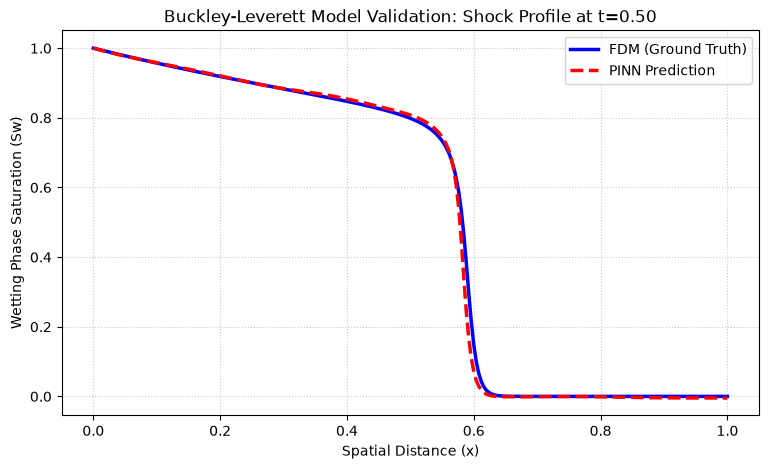

In [23]:
# switching model to evaluation mode
model.eval()

# generating the Finite Difference baseline for ground-truth comparison
x_fdm, t_fdm, Sw_fdm = generate_fdm_data()

# creating a dense spatiotemporal grid for PINN inference
X, T = np.meshgrid(x_fdm, t_fdm)
X_flat = torch.tensor(X.flatten()[:, None], dtype=torch.float32).to(device)
T_flat = torch.tensor(T.flatten()[:, None], dtype=torch.float32).to(device)

# concatenating flattened grid points for the Sequential model
inputs_flat = torch.cat([X_flat, T_flat], dim=1)

# generating predictions without tracking gradients
with torch.no_grad():
    Sw_pred_flat = model(inputs_flat).cpu().numpy()
    
# reshaping predictions back to the 2D grid format (Nt x Nx)
Sw_pred = Sw_pred_flat.reshape(X.shape)

# computing the relative L2 Error between the PINN and the numerical baseline
error_l2 = np.linalg.norm(Sw_fdm - Sw_pred) / np.linalg.norm(Sw_fdm)
print(f"Relative L2 Error against FDM Benchmark: {error_l2 * 100:.2f}%\n")

# extracting the index corresponding to t=0.5 for the shock profile visualization
idx_t = len(t_fdm) // 2
current_time = t_fdm[idx_t]

# plotting the comparison
plt.figure(figsize=(9, 5))
plt.plot(x_fdm, Sw_fdm[idx_t, :], 'b-', linewidth=2.5, label="FDM (Ground Truth)")
plt.plot(x_fdm, Sw_pred[idx_t, :], 'r--', linewidth=2.5, label="PINN Prediction")

plt.title(f"Buckley-Leverett Model Validation: Shock Profile at t={current_time:.2f}")
plt.xlabel("Spatial Distance (x)")
plt.ylabel("Wetting Phase Saturation (Sw)")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.7)

plt.savefig("../results/validation_shock_profile.png", dpi=300, bbox_inches="tight")

plt.show()

### #6 Exporting the model

In [21]:
# Define the export path
model_path = "../models/pinn_trained.pt"

# Save the model's state dictionary
torch.save(model.state_dict(), model_path)

print(f"Model successfully exported to: {model_path}")

Model successfully exported to: ../models/pinn_trained.pt
